In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold, train_test_split

DATA_URL = (
    "https://raw.githubusercontent.com/DataTalksClub/"
    "machine-learning-zoomcamp/main/cohorts/2026/data/"
    "course_lead_scoring_2026.csv"
)
df = pd.read_csv(DATA_URL)
print(f"Dataset dimensions: {df.shape}")
display(df.head())
print("Missing values by column:")
display(df.isna().sum().to_frame("missing"))

Dataset dimensions: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


Missing values by column:


,missing
lead_source,148
industry,240
employment_status,194
location,208
annual_income,369
number_of_courses_viewed,0
interaction_count,0
lead_score,35
converted,0


In [2]:
target = "converted"
categorical = df.select_dtypes(include=["object", "string", "category"]).columns.tolist()
numerical = [column for column in df.columns
             if column not in categorical and column != target]
df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

print("Categorical features:", categorical)
print("Numerical features:", numerical)
print(f"Train / validation / test: {len(df_train)} / {len(df_val)} / {len(df_test)}")
assert not df.isna().any().any(), "Missing values remain after imputation"
assert len(df_train) + len(df_val) + len(df_test) == len(df)

Categorical features: ['lead_source', 'industry', 'employment_status', 'location']
Numerical features: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
Train / validation / test: 3000 / 1000 / 1000


In [3]:
candidate_features = [
    "lead_score", "number_of_courses_viewed", "interaction_count", "annual_income"
]
feature_auc = {}
for feature in candidate_features:
    auc = roc_auc_score(df_train[target], df_train[feature])
    feature_auc[feature] = max(auc, 1.0 - auc)
q1_scores = pd.Series(feature_auc, name="ROC AUC").sort_values(ascending=False)
display(q1_scores.to_frame())
q1_answer = q1_scores.index[0]
print("Q1 answer:", q1_answer)

,ROC AUC
lead_score,0.788225
interaction_count,0.764920
number_of_courses_viewed,0.722989
annual_income,0.608198


Q1 answer: lead_score


In [4]:
def train_and_predict(train_frame, val_frame, C=1.0):
    train_records = train_frame.drop(columns=[target]).to_dict(orient="records")
    val_records = val_frame.drop(columns=[target]).to_dict(orient="records")
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_records)
    X_val = dv.transform(val_records)
    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
    model.fit(X_train, train_frame[target].to_numpy())
    return model.predict_proba(X_val)[:, 1]
val_probabilities = train_and_predict(df_train, df_val)
y_val = df_val[target].to_numpy()
q2_auc = roc_auc_score(y_val, val_probabilities)
q2_choices = [0.532, 0.632, 0.732, 0.832]
q2_answer = min(q2_choices, key=lambda v: abs(v - q2_auc))
print(f"Validation ROC AUC: {q2_auc:.6f}")
print(f"Q2 answer (nearest offered choice): {q2_answer:.3f}")

Validation ROC AUC: 0.731822
Q2 answer (nearest offered choice): 0.732


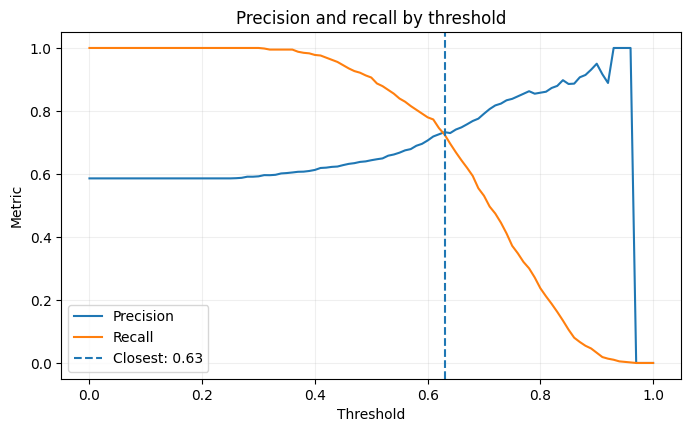

Closest intersection values:


,threshold,precision,recall,f1,difference
63,0.63,0.732759,0.725256,0.728988,0.007503


Q3 answer (nearest offered choice): 0.63


In [5]:
thresholds = np.linspace(0.0, 1.0, 101)
rows = []
for threshold in thresholds:
    predicted_positive = val_probabilities >= threshold
    tp = np.sum(predicted_positive & (y_val == 1))
    fp = np.sum(predicted_positive & (y_val == 0))
    fn = np.sum(~predicted_positive & (y_val == 1))
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    rows.append((threshold, precision, recall, f1))

metrics = pd.DataFrame(rows, columns=["threshold", "precision", "recall", "f1"])
nonzero = metrics.loc[(metrics.precision != 0) | (metrics.recall != 0)].copy()
nonzero["difference"] = (nonzero.precision - nonzero.recall).abs()
q3_row = nonzero.sort_values(["difference", "threshold"]).iloc[0]
q3_choices = [0.43, 0.63, 0.73, 0.83]
q3_answer = min(q3_choices, key=lambda v: abs(v - q3_row.threshold))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(metrics.threshold, metrics.precision, label="Precision")
ax.plot(metrics.threshold, metrics.recall, label="Recall")
ax.axvline(q3_row.threshold, linestyle="--", label=f"Closest: {q3_row.threshold:.2f}")
ax.set(xlabel="Threshold", ylabel="Metric", title="Precision and recall by threshold")
ax.grid(alpha=0.2)
ax.legend()
plt.show()
print("Closest intersection values:")
display(q3_row.to_frame().T)
print(f"Q3 answer (nearest offered choice): {q3_answer:.2f}")

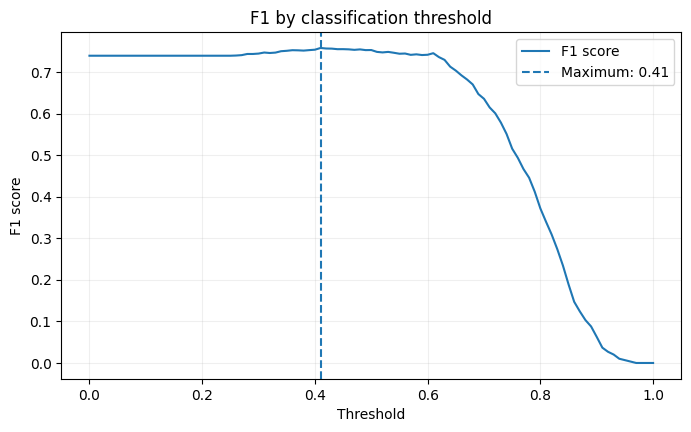

Maximum F1: 0.757616 at threshold 0.41
Q4 answer (nearest offered choice): 0.41


In [6]:
q4_row = metrics.loc[metrics.f1.idxmax()]
q4_choices = [0.21, 0.41, 0.61, 0.81]
q4_answer = min(q4_choices, key=lambda v: abs(v - q4_row.threshold))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(metrics.threshold, metrics.f1, label="F1 score")
ax.axvline(q4_row.threshold, linestyle="--", label=f"Maximum: {q4_row.threshold:.2f}")
ax.set(xlabel="Threshold", ylabel="F1 score", title="F1 by classification threshold")
ax.grid(alpha=0.2)
ax.legend()
plt.show()
print(f"Maximum F1: {q4_row.f1:.6f} at threshold {q4_row.threshold:.2f}")
print(f"Q4 answer (nearest offered choice): {q4_answer:.2f}")

In [7]:
def evaluate_C(full_train_frame, C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    aucs = []
    for train_idx, val_idx in kfold.split(full_train_frame):
        fold_train = full_train_frame.iloc[train_idx]
        fold_val = full_train_frame.iloc[val_idx]
        fold_probs = train_and_predict(fold_train, fold_val, C=C)
        aucs.append(roc_auc_score(fold_val[target].to_numpy(), fold_probs))
    return np.asarray(aucs)

q5_fold_scores = evaluate_C(df_full_train, C=1.0)
q5_std = float(np.std(q5_fold_scores))
q5_choices = [0.001, 0.007, 0.013, 0.060]
q5_answer = min(q5_choices, key=lambda v: abs(v - q5_std))
print("AUC by fold:", np.round(q5_fold_scores, 6))
print(f"Mean ROC AUC: {q5_fold_scores.mean():.6f}")
print(f"Standard deviation: {q5_std:.6f}")
print(f"Q5 answer (nearest offered choice): {q5_answer:.3f}")

AUC by fold: [0.73056  0.729573 0.736343 0.741245 0.720914]
Mean ROC AUC: 0.731727
Standard deviation: 0.006853
Q5 answer (nearest offered choice): 0.007


In [8]:
C_values = [0.000001, 0.001, 1.0]
cv_rows = []
for C in C_values:
    fold_scores = evaluate_C(df_full_train, C=C)
    cv_rows.append({"C": C, "mean_auc": np.mean(fold_scores),
                    "std_auc": np.std(fold_scores)})

cv_results = pd.DataFrame(cv_rows)
cv_results["rounded_mean"] = cv_results.mean_auc.round(3)
cv_results["rounded_std"] = cv_results.std_auc.round(3)
display(cv_results)
ranked = cv_results.sort_values(
    ["rounded_mean", "rounded_std", "C"], ascending=[False, True, True]
)
q6_answer = ranked.iloc[0].C
print(f"Q6 answer: C = {q6_answer:g}")

,C,mean_auc,std_auc,rounded_mean,rounded_std
0,0.000001,0.616734,0.018670,0.617,0.019
1,0.001000,0.749172,0.009996,0.749,0.010
2,1.000000,0.731727,0.006853,0.732,0.007


Q6 answer: C = 0.001


In [9]:
submission = pd.DataFrame([
    ("Q1 — Feature ROC AUC", q1_answer),
    ("Q2 — Model ROC AUC", f"{q2_answer:.3f}"),
    ("Q3 — Precision/recall crossing", f"{q3_answer:.2f}"),
    ("Q4 — Maximum F1 threshold", f"{q4_answer:.2f}"),
    ("Q5 — 5-fold AUC std", f"{q5_answer:.3f}"),
    ("Q6 — Best C", f"{q6_answer:g}"),
], columns=["Question", "Selection"])
display(submission)

,Question,Selection
0,Q1 — Feature ROC AUC,lead_score
1,Q2 — Model ROC AUC,0.732
2,Q3 — Precision/recall crossing,0.63
3,Q4 — Maximum F1 threshold,0.41
4,Q5 — 5-fold AUC std,0.007
5,Q6 — Best C,0.001
